# 8. Transport planning

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/08_planning.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/08_planning.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

You make the GMNS network of Monaco, check it, load it in path4gmns and find a shortest path there. The module is `duckosm.planning`. [duckOSM for transport planning users](https://khoshkhah.github.io/duckOSM/compare/for-planning-users/) compares each call with osm2gmns, path4gmns and AequilibraE.

| Call | Result |
|---|---|
| `net.to_gmns` (`duckosm.planning.to_gmns`) | the GMNS tables: links, nodes, lanes, movements |
| `duckosm.planning.check_gmns` | the checks of the tables |
| `duckosm.planning.to_path4gmns` | the network loaded in path4gmns |
| `duckosm.planning.to_aequilibrae` | an AequilibraE project (needs AequilibraE and SpatiaLite; not run here) |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
# Until duckOSM 0.9.0 is on PyPI, the SDK of these notebooks is in the nightly wheel of main (the GitHub pre-release "nightly").
import importlib.util, json, urllib.request
def nightly_wheel():       # the address of the newest nightly wheel
    release = json.load(urllib.request.urlopen("https://api.github.com/repos/Khoshkhah/duckOSM/releases/tags/nightly"))
    return next(a["browser_download_url"] for a in release["assets"] if a["name"].endswith(".whl"))
if importlib.util.find_spec("duckosm") is None:      # not installed: install it with the extras of this notebook
    %pip install -q "duckosm[sim,planning] @ {nightly_wheel()}"
import duckosm             # the SDK
if not hasattr(duckosm, "network"):                    # an old duckOSM (0.8.0 or older), without the SDK
    %pip install -q --force-reinstall --no-deps "duckosm @ {nightly_wheel()}"
    raise SystemExit("duckOSM is updated: restart the session (in Colab: Runtime > Restart session), then run this cell again")
print("duckosm", duckosm.__version__)    # the version

duckosm 0.8.0


In [2]:
net = duckosm.network(osm_id=2220322, modes=["driving"], name="monaco")    # get and build the driving network of Monaco
net                                                   # the card

cut: 34461 nodes, 5685 ways, 339 relations

Output: data/monaco.duckdb

mode,edges,nodes,km,oneway_km
driving,2840,1768,96.2,35.5


## GMNS

`to_gmns` writes the GMNS tables in a DuckDB file. The `link_id` of each link is the `edge_id`. The lanes and the movements come from SUMO's netconvert (the extra `sim`).

In [3]:
net.driving.to_gmns("out/gmns.duckdb")                       # the GMNS tables
checks = duckosm.planning.check_gmns("out/gmns.duckdb")      # (schema, check, bad rows, rows) for each check
len(checks), [c for c in checks if c[2] > 0]                 # the number of checks, and the checks with bad rows

GMNS out/gmns.duckdb: done in 6.6 s

(17, [])

In [4]:
import duckdb                                                # to read the GMNS tables

gmns = duckdb.connect("out/gmns.duckdb", read_only=True)     # the GMNS file
gmns.sql("""SELECT 'link' AS table_name, count(*) AS rows FROM gmns_driving.link
            UNION ALL SELECT 'node', count(*) FROM gmns_driving.node
            UNION ALL SELECT 'lane', count(*) FROM gmns_driving.lane
            UNION ALL SELECT 'movement', count(*) FROM gmns_driving.movement""").df()    # the rows of the main tables

,table_name,rows
0,link,2858
1,node,1772
2,lane,3318
3,movement,3755


## path4gmns

`to_path4gmns` writes `node.csv` and `link.csv` and loads them with path4gmns, with lengths in metres and speeds in km/h. The node ids are the OSM node ids, so the ends of a duckOSM route are nodes of path4gmns too.

In [5]:
pnet = duckosm.planning.to_path4gmns("out/gmns.duckdb")    # the network in path4gmns

path4gmns, version 0.10.0

read node.csv
the number of nodes is 1,772
the number of zones is 1

read link.csv
the number of links is 2,858



In [6]:
route = net.route((7.4155, 43.7285), (7.4335, 43.7468), weight="length")    # the shortest route in duckOSM
ends = net.edges(where=f"edge_id IN ({route['edges'][0]}, {route['edges'][-1]})").set_index("edge_id")
start, end = int(ends.source[route["edges"][0]]), int(ends.target[route["edges"][-1]])    # its first and last node
found = pnet.find_shortest_path(start, end, mode="auto", seq_type="link", cost_type="distance")    # the same in path4gmns
links = [int(x) for x in found.split("link path: ")[1].split(";")]                            # its links (edge ids)
round(route["length_m"]), found.split(" | ")[0], links == route["edges"]    # the two lengths, and the same edges?

(2937, 'path distance: 2917.8829 meters', True)

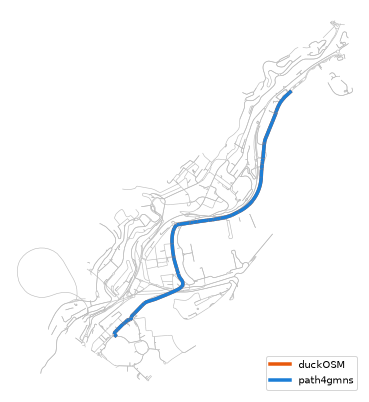

In [7]:
net.map(routes={"duckOSM": route, "path4gmns": {"edges": links}})    # the two routes on the map